# Multimodal RAG over "Attention Is All You Need"

## 1. Assignment overview

The task is a Retrieval-Augmented Generation system, built from scratch, that answers
questions about the paper *Attention Is All You Need*
([NeurIPS PDF](https://proceedings.neurips.cc/paper_files/paper/2017/file/3f5ee243547dee91fbd053c1c4a845aa-Paper.pdf)).

| Component | Implementation |
|---|---|
| Document ingestion | PyMuPDF text blocks, embedded images and caption-anchored figure/table renders |
| Embeddings | `jinaai/jina-clip-v1`, one 768-d space for text and images |
| Vector database | ChromaDB (persistent, cosine) with an index manifest |
| Retrieval | text top-k plus visuals scored by fused pixel and caption similarity |
| Generation | `microsoft/Phi-3-vision-128k-instruct`, given the retrieved text and the retrieved figure pixels |

This notebook is a thin interface over the tested modules in `src/`, which keep the logic
in one place. Every stage has an explanation, the call, a **verification** cell and its
output. The notebook runs top to bottom. The PDF is processed once, the index is built
once (and reused when it already exists), and each model is loaded once.

## 2. Requirements and constraints

* **Allowed libraries:** `torch, chromadb, numpy, io, fitz, requests, PIL, transformers`.
  `src/` imports nothing else from outside the standard library; this is checked in the
  next cell. `torchvision`, `timm`, `einops` and `accelerate` are installed only because the
  mandated models' remote code needs them.
* **Hardware used for this run:** CPU only (Intel i7-1185G7, 4 cores) with about 10 GB of
  free RAM. Phi-3-V therefore runs in bfloat16 with at most one image per prompt, and each
  answer takes 1–3 minutes.

**Traceability matrix:** where each requirement is implemented and how it is verified.

| Requirement | Implementation | Verification (this notebook / tests) |
|---|---|---|
| PDF ingestion | `src/document_loader.py` | §5 checks; `tests/test_document_loader.py` (download, retry, corrupt, encrypted, empty) |
| Text extraction | `src/text_extractor.py`, `src/preprocessing.py` | §6 checks; `tests/test_preprocessing.py` |
| Image extraction | `src/image_extractor.py` | §7 renders and checks; `ExtractionTests` |
| Text and image embeddings | `src/embedding_service.py` | §8 shape, finiteness and norm checks; `tests/test_embeddings.py` |
| Vector persistence | `src/vector_store.py`, `src/indexer.py` | §9 build or reuse and manifest; `tests/test_vector_store.py`, `tests/test_pipeline.py` |
| Multimodal retrieval | `src/retriever.py` | §10 and §15 metrics; `tests/test_retrieval.py` |
| Context construction | `src/context_builder.py` | §11; `ContextBuilderTests` |
| Answer generation | `src/generator.py` | §12–14 live answers; `tests/test_generation.py` |
| Error handling | every module | negative tests in each test file |
| Logging | `src/logging_config.py` | log output below; `test_logging_configured_once` |
| Documentation | `README.md`, `docs/` | – |

In [1]:
# Dependency audit: every non-standard-library import used by src/
import ast, sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pipeline.py").exists())
sys.path.insert(0, str(ROOT))

third_party = set()
for f in (ROOT / "src").glob("*.py"):
    for node in ast.walk(ast.parse(f.read_text())):
        names = ([a.name for a in node.names] if isinstance(node, ast.Import)
                 else [node.module] if isinstance(node, ast.ImportFrom) and node.level == 0 else [])
        for n in names:
            top = n.split(".")[0]
            if top not in sys.stdlib_module_names:
                third_party.add(top)
ALLOWED = {"torch", "chromadb", "numpy", "io", "fitz", "requests", "PIL", "transformers"}
print("third-party imports in src/:", sorted(third_party))
assert third_party <= ALLOWED, third_party - ALLOWED
print("OK - all within the allow-list")

third-party imports in src/: ['PIL', 'chromadb', 'fitz', 'numpy', 'requests', 'torch', 'transformers']
OK - all within the allow-list


## 3. Configuration

All settings live in `config/config.json`. They are validated before any expensive work
starts, and the README documents every key with its range and default.

In [2]:
import json
from src.config import load_config

cfg = load_config()
print(json.dumps({k: v for k, v in cfg.to_dict().items()
                  if k in ("chunking", "images", "retrieval", "context", "generation")}, indent=1))

{
 "chunking": {
  "chunk_size_chars": 900,
  "chunk_overlap_chars": 150,
  "min_chunk_chars": 80,
  "exclude_references": true,
  "parser": "layout"
 },
 "images": {
  "render_dpi": 200,
  "min_image_side_px": 64,
  "max_image_side_px": 2048,
  "extract_tables": true,
  "output_dir": "data/processed/visuals"
 },
 "retrieval": {
  "mode": "multimodal",
  "top_k_text": 5,
  "top_k_image": 2,
  "visual_scoring": "fused",
  "min_visual_score": 0.4,
  "structure_routing": false,
  "top_k_sections": 2,
  "routed_text_slots": 3
 },
 "context": {
  "max_context_chars": 3600,
  "max_images": 1
 },
 "generation": {
  "model_id": "microsoft/Phi-3-vision-128k-instruct",
  "revision": "ed2772fabe9dc9acd0caad54b62761d92520cc44",
  "device": "auto",
  "dtype": "bfloat16",
  "num_crops": 4,
  "max_new_tokens": 200,
  "max_input_tokens": 4096,
  "do_sample": false,
  "temperature": 0.0,
  "repetition_penalty": 1.0,
  "attn_implementation": "eager"
 }
}


## 4. Imports and logging

Logging is configured once, to the console and to `logs/rag.log`, and every line carries a
run id.

In [3]:
import time
import numpy as np
import torch
from PIL import Image

from src.logging_config import setup_logging, get_run_id
from src.document_loader import load_document, open_pdf
from src.text_extractor import extract_text
from src.preprocessing import chunk_blocks
from src.image_extractor import extract_visuals
from src.pipeline import RAGPipeline
from src.context_builder import build_context, default_image_loader
from src.generator import build_prompt_text

log = setup_logging(cfg)
print("run id:", get_run_id(), "| torch", torch.__version__, "| threads", torch.get_num_threads(),
      "| CUDA available:", torch.cuda.is_available())

run id: fee43ce7 | torch 2.5.1+cpu | threads 4 | CUDA available: False


## 5. PDF loading

The loader reuses a valid local copy. Otherwise it downloads to a `.part` file with
bounded retries (transient errors only), checks that the bytes are a readable,
unencrypted PDF with pages, and only then renames the file into place.

In [4]:
t = time.perf_counter()
doc_info = load_document(cfg.document, cfg.path)
print(f"loaded in {time.perf_counter() - t:.2f}s")
doc_info.to_dict()

2026-10-31 16:57:39,773 | INFO     | src.document_loader | run=fee43ce7 | Reusing local PDF /home/tathagata/Desktop/TEST_MULTIMODAL_RAG/data/raw/attention_is_all_you_need.pdf (11 pages, sha256=d87d482d5ae7)


loaded in 0.02s


{'path': '/home/tathagata/Desktop/TEST_MULTIMODAL_RAG/data/raw/attention_is_all_you_need.pdf',
 'filename': 'attention_is_all_you_need.pdf',
 'source': 'https://proceedings.neurips.cc/paper_files/paper/2017/file/3f5ee243547dee91fbd053c1c4a845aa-Paper.pdf',
 'sha256': 'd87d482d5ae7960e2e43d7dd6d21377e60e73e8fce1bf2a01aff7aca8a08c537',
 'page_count': 11,
 'title': 'Attention is All you Need',
 'size_bytes': 569417,
 'loaded_at': '2026-10-31T11:27:39+00:00',
 'doc_id': 'd87d482d5ae7'}

In [5]:
# Verification
assert doc_info.page_count == 11
assert doc_info.sha256.startswith("d87d482d")
print("PDF valid:", doc_info.filename, doc_info.page_count, "pages, doc_id", doc_info.doc_id)

PDF valid: attention_is_all_you_need.pdf 11 pages, doc_id d87d482d5ae7


## 6. Layout-aware text extraction and chunking

The paper has no PDF outline, so its structure is **recovered from typography**: font
sizes and weights, position on the page, and math fonts. Each block gets a role:
heading at level *n*, paragraph, equation, caption, table, footnote, page number or
running footer. The headings form a table of contents (ToC). This follows STAIR
(arXiv:2609.03874), which argues that ToC entries make better retrieval units than
length-based chunks because they are semantically coherent and clearly bounded.

Chunking then:
* packs whole paragraphs into chunks of at most **900 characters** inside one ToC section,
  splitting only oversized paragraphs, at sentence boundaries, with **≤ 150 characters**
  of trailing-sentence overlap;
* prefixes each chunk with its **full section path**, for example
  `[3 Model Architecture > 3.2 Attention > 3.2.1 Scaled Dot-Product Attention]`;
* keeps equations with the paragraph that introduces them, and turns captions, tables and
  footnotes into their own units;
* drops page numbers and the venue footer, and excludes References.

In [6]:
from src.layout_parser import parse_layout, layout_paragraphs
from src.preprocessing import pack_paragraphs

with open_pdf(doc_info.path) as pdf:
    layout = parse_layout(pdf)
print("body font:", layout.body_size, "pt | roles:", layout.role_counts)
print("\nRecovered table of contents:")
print("\n".join("  " + t for t in layout.toc()))
chunks = pack_paragraphs(layout_paragraphs(layout, cfg.chunking.exclude_references), cfg.chunking, doc_info.doc_id)
sizes = [c.char_count for c in chunks]
print(f"\n{len(chunks)} chunks; size min/mean/max = {min(sizes)}/{np.mean(sizes):.0f}/{max(sizes)} chars")
for c in chunks[19:22]:
    print(f"\n{c.chunk_id}  pages {c.page_start}-{c.page_end}\n  {c.text[:300]}...")

2026-10-31 16:57:39,809 | INFO     | src.layout_parser | run=fee43ce7 | Layout: body=10.0pt, 219 blocks {'title': 1, 'front_matter': 11, 'heading': 23, 'paragraph': 126, 'footnote': 5, 'header_footer': 1, 'page_number': 10, 'caption': 5, 'equation': 16, 'table': 21}, 23 sections (outline=False)


2026-10-31 16:57:39,812 | INFO     | src.preprocessing | run=fee43ce7 | Chunked 74 paragraphs into 53 chunks (size=900, overlap=150)


body font: 10.0 pt | roles: {'title': 1, 'front_matter': 11, 'heading': 23, 'paragraph': 126, 'footnote': 5, 'header_footer': 1, 'page_number': 10, 'caption': 5, 'equation': 16, 'table': 21}

Recovered table of contents:
  Abstract
  1 Introduction
  2 Background
  3 Model Architecture
    3.1 Encoder and Decoder Stacks
    3.2 Attention
      3.2.1 Scaled Dot-Product Attention
      3.2.2 Multi-Head Attention
      3.2.3 Applications of Attention in our Model
    3.3 Position-wise Feed-Forward Networks
    3.4 Embeddings and Softmax
    3.5 Positional Encoding
  4 Why Self-Attention
  5 Training
    5.1 Training Data and Batching
    5.2 Hardware and Schedule
    5.3 Optimizer
    5.4 Regularization
  6 Results
    6.1 Machine Translation
    6.2 Model Variations
  7 Conclusion
  References

53 chunks; size min/mean/max = 71/565/1045 chars

d87d482d5ae7-text-0019  pages 4-4
  [3 Model Architecture > 3.2 Attention > 3.2.1 Scaled Dot-Product Attention] query with all keys, divide each b

In [7]:
# Verification: structure, provenance, furniture removed, deterministic ids
assert layout.toc()[3] == "3 Model Architecture" and "    3.2.1 Scaled Dot-Product Attention" in layout.toc()
assert len({c.chunk_id for c in chunks}) == len(chunks)
assert all(1 <= c.page_start <= c.page_end <= 11 for c in chunks)
assert not any("31st Conference on Neural Information" in c.text for c in chunks)   # venue footer dropped
assert not any(c.section_path.startswith("References") for c in chunks)
footnotes = [c for c in chunks if c.section == "Footnote"]
print("footnote chunks:", [c.section_path for c in footnotes])

footnote chunks: ['1 Introduction > Footnote', '1 Introduction > Footnote', '3 Model Architecture > 3.2 Attention > 3.2.2 Multi-Head Attention > Footnote', '6 Results > 6.2 Model Variations > Footnote']


## 7. Image and figure extraction

* **Embedded raster extraction** (`extract_image`) returns the image bytes stored in the
  PDF. They are decoded with Pillow, size-checked and de-duplicated. On their own they are
  fragments: Figure 2 is two separate rasters, and its panel titles are PDF text.
* **Region rendering** (`get_pixmap(clip=…)`) rasterises part of the page as a reader sees
  it. Tables 1–3 are vector drawings and exist only this way.

Each `Figure N:` / `Table N:` caption anchors **one rendered region**, giving complete,
captioned visuals without full-page renders.

In [8]:
with open_pdf(doc_info.path) as pdf:
    img_res = extract_visuals(pdf, cfg.images, doc_info.doc_id,
                              cfg.path(cfg.images.output_dir), cfg.project_root)
print("embedded rasters:", [(e.page, e.xref, f"{e.width}x{e.height}") for e in img_res.embedded])
print("rejected:", img_res.rejected)
for v in img_res.visuals:
    print(f"{v.visual_id:<24} {v.label:<9} page {v.page}  {v.width}x{v.height}  source={v.source}")

2026-10-31 16:57:40,499 | INFO     | src.image_extractor | run=fee43ce7 | Images: 3 embedded accepted, 0 rejected; 5 visual records (Figure 1, Figure 2, Table 1, Table 2, Table 3)


embedded rasters: [(3, 94, '1520x2239'), (4, 102, '835x1282'), (4, 104, '445x884')]
rejected: []
d87d482d5ae7-figure-01   Figure 1  page 3  642x985  source=embedded_raster_region
d87d482d5ae7-figure-02   Figure 2  page 4  1134x654  source=embedded_raster_region
d87d482d5ae7-table-01    Table 1   page 6  1135x344  source=vector_region
d87d482d5ae7-table-02    Table 2   page 8  1135x501  source=vector_region
d87d482d5ae7-table-03    Table 3   page 9  1135x898  source=vector_region


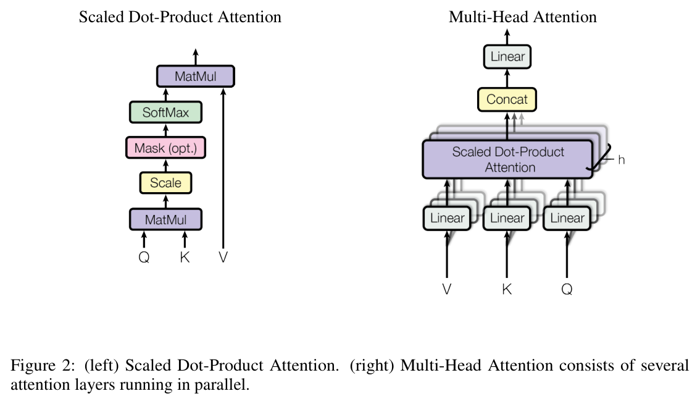

In [9]:
# Verification: every visual decodes, is RGB and matches its recorded size
for v in img_res.visuals:
    with Image.open(cfg.path(v.path)) as im:
        assert im.mode == "RGB" and im.size == (v.width, v.height)
assert [v.label for v in img_res.visuals] == ["Figure 1", "Figure 2", "Table 1", "Table 2", "Table 3"]
fig2 = Image.open(cfg.path(img_res.visuals[1].path))
fig2.thumbnail((700, 700)); fig2

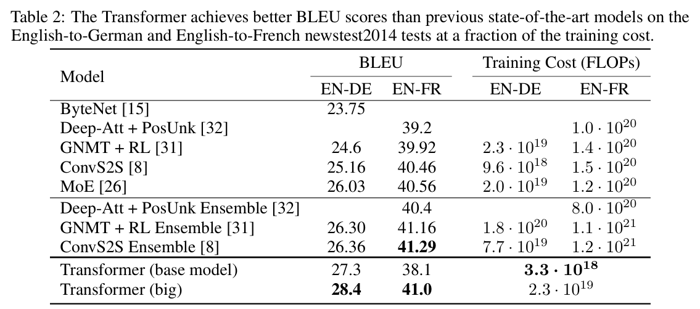

In [10]:
tab2 = Image.open(cfg.path(img_res.visuals[3].path)); tab2.thumbnail((700, 700)); tab2

## 8. Text and image embeddings (Jina CLIP v1)

I checked the model API in its source code before using it: `encode_text` and
`encode_image` exist, run in inference mode, and return L2-normalised 768-d vectors in a
**shared** text/image space. The service adds its own batching with OOM back-off and
validates the shape, finiteness and unit norm of every vector.

In [11]:
pipeline = RAGPipeline(cfg)           # owns the single instances of both models
emb = pipeline.embedder
probe_q = ["scaled dot-product attention diagram", "BLEU scores compared with other models",
           "complexity per layer of self-attention, recurrent and convolutional layers"]
q_vecs = emb.embed_texts(probe_q)
visuals = [Image.open(cfg.path(v.path)).convert("RGB") for v in img_res.visuals]
v_vecs = emb.embed_images(visuals)
print("text", q_vecs.shape, "image", v_vecs.shape, "| model load", round(emb.load_seconds, 2), "s")
print("cross-modal cosine similarity (rows = queries, cols =", [v.label for v in img_res.visuals], ")")
print(np.round(q_vecs @ v_vecs.T, 3))

/home/tathagata/Desktop/TEST_MULTIMODAL_RAG/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-10-31 16:57:42,061 | INFO     | src.embedding_service | run=fee43ce7 | Loaded jinaai/jina-clip-v1 on cpu in 1.5s (revision ceb3e44ca4d6eceaa4f3fb58b1c1a5748b3f29b6)


text (3, 768) image (5, 768) | model load 1.46 s
cross-modal cosine similarity (rows = queries, cols = ['Figure 1', 'Figure 2', 'Table 1', 'Table 2', 'Table 3'] )
[[ 0.156  0.311  0.06  -0.01   0.084]
 [ 0.058  0.05   0.008  0.311  0.147]
 [ 0.128  0.149  0.243  0.092  0.108]]


In [12]:
# Verification: shared space works - each probe's best visual is the expected one
assert q_vecs.shape[1] == v_vecs.shape[1] == 768
assert np.isfinite(q_vecs).all() and np.allclose(np.linalg.norm(v_vecs, axis=1), 1, atol=1e-3)
labels = [v.label for v in img_res.visuals]
print([labels[i] for i in (q_vecs @ v_vecs.T).argmax(axis=1)])
assert [labels[i] for i in (q_vecs @ v_vecs.T).argmax(axis=1)] == ["Figure 2", "Table 2", "Table 1"]

['Figure 2', 'Table 2', 'Table 1']


## 9. ChromaDB initialisation and indexing

Indexing runs through the decoupled ingestion service (`src/ingestion/`; batch, streaming
and incremental modes are described in `docs/ingestion.md`). `pipeline.index()` does one
of two things:
* it **ingests** the paper: process, embed text chunks, ToC section records and visuals,
  upsert into a cosine collection with document-prefixed deterministic IDs, verify the
  count and record the document in `storage/registry.json`; or
* it **reuses** the existing index when the content hash and index fingerprint are
  unchanged, recomputing nothing.

A changed model, parser, chunking or image setting makes it refuse with instructions to
`--rebuild`.

In [13]:
report = pipeline.index()
print(report.summary())
again = pipeline.index()                     # second call must reuse
print(again.summary())

2026-10-31 16:57:42,743 | INFO     | src.document_loader | run=fee43ce7 | Reusing local PDF /home/tathagata/Desktop/TEST_MULTIMODAL_RAG/data/raw/attention_is_all_you_need.pdf (11 pages, sha256=d87d482d5ae7)


2026-10-31 16:57:42,760 | INFO     | src.ingestion.service | run=fee43ce7 | Unchanged: attention_is_all_you_need.pdf (doc_id d87d482d5ae7) already indexed


2026-10-31 16:57:42,761 | INFO     | src.indexer | run=fee43ce7 | Index reused: 53 text chunks + 21 ToC sections + 5 visuals = 79 records | load_pdf=0.02s


2026-10-31 16:57:42,777 | INFO     | src.document_loader | run=fee43ce7 | Reusing local PDF /home/tathagata/Desktop/TEST_MULTIMODAL_RAG/data/raw/attention_is_all_you_need.pdf (11 pages, sha256=d87d482d5ae7)


2026-10-31 16:57:42,794 | INFO     | src.ingestion.service | run=fee43ce7 | Unchanged: attention_is_all_you_need.pdf (doc_id d87d482d5ae7) already indexed


2026-10-31 16:57:42,795 | INFO     | src.indexer | run=fee43ce7 | Index reused: 53 text chunks + 21 ToC sections + 5 visuals = 79 records | load_pdf=0.02s


Index reused: 53 text chunks + 21 ToC sections + 5 visuals = 79 records | load_pdf=0.02s
Index reused: 53 text chunks + 21 ToC sections + 5 visuals = 79 records | load_pdf=0.02s


In [14]:
# Verification: persisted counts, modality split, registry status, no duplicates on re-run
store = pipeline.store
counts = {m: store.count({"modality": m}) for m in ("text", "section", "image")}
entry = pipeline.ingestion.registry.get(doc_info.doc_id)
print(f"collection '{store.collection_name}': {store.count()} records {counts}")
print("registry entry:", {k: getattr(entry, k) for k in ("status", "total_records", "fingerprint_hash")})
assert again.action == "reused" and store.count() == entry.total_records == sum(counts.values())
assert counts["image"] == 5 and counts["section"] > 15

collection 'attention_paper_mm': 79 records {'text': 53, 'section': 21, 'image': 5}
registry entry: {'status': 'indexed', 'total_records': 79, 'fingerprint_hash': '88fed0bcc2d1d59c'}


## 10. Retrieval

* Text: Chroma top-5 among `modality == text`.
* Visuals: text-to-image cosine similarities from Jina CLIP (about 0.05–0.35) are much
  lower than text-to-text ones (about 0.3–0.8), so visuals get their own quota. The
  **fused score** is the mean of the query-to-pixels and query-to-caption-chunk cosines.
  Both are real Jina CLIP similarities, and an image is attached only if the score is
  ≥ 0.40 (§15 measures this choice).

In [15]:
def show(res):
    print(f"Q: {res.query}  [mode={res.mode}]")
    for t in res.text:
        print(f"  T{t.rank} {t.similarity:.3f} p.{t.metadata['page_start']}-{t.metadata['page_end']} "
              f"[{t.metadata['section'][:45]}]")
    for i in res.images:
        print(f"  I{i.rank} {i.similarity:.3f} {i.scores} {i.metadata['label']} (p.{i.page})")
    for i in res.rejected_images:
        print(f"  (rejected visual {i.metadata['label']} score {i.similarity:.3f})")

show(pipeline.retrieve("What BLEU score did the big Transformer achieve on English-to-German?"))
show(pipeline.retrieve("How does the decoder prevent attending to subsequent positions?"))
show(pipeline.retrieve("scaled dot-product attention diagram", mode="image"))
print()
# STAIR-style structure routing: pick ToC sections first, then chunks inside them
r = pipeline.retrieve("How does the decoder prevent attending to subsequent positions?", structure_routing=True)
print("routed sections:", [(s.metadata["section_path"], round(s.similarity, 3)) for s in r.sections])
show(r)

2026-10-31 16:57:42,852 | INFO     | src.retriever | run=fee43ce7 | Retrieved 5 text + 1 image records (mode=multimodal, visual=fused, 1 below threshold) in 0.040s


2026-10-31 16:57:42,902 | INFO     | src.retriever | run=fee43ce7 | Retrieved 5 text + 0 image records (mode=multimodal, visual=fused, 3 below threshold) in 0.049s


Q: What BLEU score did the big Transformer achieve on English-to-German?  [mode=multimodal]
  T1 0.680 p.8-8 [6.1 Machine Translation]
  T2 0.613 p.8-8 [Table 2: The Transformer achieves better BLEU]
  T3 0.555 p.9-9 [Table 3: Variations on the Transformer archit]
  T4 0.528 p.1-1 [Abstract]
  T5 0.480 p.8-8 [6.1 Machine Translation]
  I1 0.421 {'pixel': 0.22926980257034302, 'caption': 0.6131888031959534} Table 2 (p.8)
  (rejected visual Table 3 score 0.322)
Q: How does the decoder prevent attending to subsequent positions?  [mode=multimodal]
  T1 0.506 p.3-3 [3.1 Encoder and Decoder Stacks]
  T2 0.474 p.5-5 [3.2.3 Applications of Attention in our Model]
  T3 0.438 p.5-5 [3.2.3 Applications of Attention in our Model]
  T4 0.429 p.2-2 [3 Model Architecture]
  T5 0.418 p.5-5 [3.5 Positional Encoding]
  (rejected visual Table 1 score 0.229)
  (rejected visual Figure 1 score 0.213)
  (rejected visual Figure 2 score 0.137)


2026-10-31 16:57:42,941 | INFO     | src.retriever | run=fee43ce7 | Retrieved 0 text + 1 image records (mode=image, visual=fused, 2 below threshold) in 0.038s


Q: scaled dot-product attention diagram  [mode=image]
  I1 0.473 {'pixel': 0.311126708984375, 'caption': 0.6348604559898376} Figure 2 (p.4)
  (rejected visual Figure 1 score 0.201)
  (rejected visual Table 1 score 0.184)



2026-10-31 16:57:43,003 | INFO     | src.retriever | run=fee43ce7 | Retrieved 5 text + 0 image records (mode=multimodal, visual=fused, 3 below threshold) in 0.061s


routed sections: [('3 Model Architecture > 3.2 Attention > 3.2.3 Applications of Attention in our Model', 0.47), ('3 Model Architecture', 0.421)]
Q: How does the decoder prevent attending to subsequent positions?  [mode=multimodal]
  T1 0.474 p.5-5 [3.2.3 Applications of Attention in our Model]
  T2 0.438 p.5-5 [3.2.3 Applications of Attention in our Model]
  T3 0.429 p.2-2 [3 Model Architecture]
  T4 0.506 p.3-3 [3.1 Encoder and Decoder Stacks]
  T5 0.418 p.5-5 [3.5 Positional Encoding]
  (rejected visual Table 1 score 0.229)
  (rejected visual Figure 1 score 0.213)
  (rejected visual Figure 2 score 0.137)


In [16]:
# Verification: modality filters and visual gating behave as specified
r = pipeline.retrieve("What BLEU score did the big Transformer achieve on English-to-German?")
assert r.text[0].page == 8 and r.images and r.images[0].metadata["label"] == "Table 2"
assert not pipeline.retrieve("Which optimizer was used?").images       # gate: no irrelevant image
assert not pipeline.retrieve("x", mode="text").images
print("retrieval checks passed")

2026-10-31 16:57:43,053 | INFO     | src.retriever | run=fee43ce7 | Retrieved 5 text + 1 image records (mode=multimodal, visual=fused, 1 below threshold) in 0.044s


2026-10-31 16:57:43,106 | INFO     | src.retriever | run=fee43ce7 | Retrieved 5 text + 0 image records (mode=multimodal, visual=fused, 3 below threshold) in 0.052s


2026-10-31 16:57:43,135 | INFO     | src.retriever | run=fee43ce7 | Retrieved 5 text + 0 image records (mode=text, visual=fused, 0 below threshold) in 0.027s


retrieval checks passed


## 11. Context construction

The context builder turns retrieval results into tagged evidence: `[I1]` for a figure
passed **as pixels** with its caption, and `[T1]…` for text, each with pages. It merges
adjacent chunks and removes their overlap, drops a caption chunk when its image is already
attached, and enforces the 3,600-character and 1-image budgets.

In [17]:
res = pipeline.retrieve("In the scaled dot-product attention diagram, which operations are applied to Q, K and V?")
ctx = build_context(res, cfg.context, default_image_loader(cfg.project_root))
print("images passed as pixels:", [(i.tag, i.label, ctx.images[k].size) for k, i in enumerate(ctx.image_items)])
print("dropped:", ctx.dropped)
print(build_prompt_text(ctx)[:1500], "...")

2026-10-31 16:57:43,186 | INFO     | src.retriever | run=fee43ce7 | Retrieved 5 text + 1 image records (mode=multimodal, visual=fused, 1 below threshold) in 0.046s


2026-10-31 16:57:43,193 | INFO     | src.context_builder | run=fee43ce7 | Context: 3 text items, 1 images, 0 dropped, 1898 chars


images passed as pixels: [('I1', 'Figure 2', (1134, 654))]
dropped: []
<|image_1|>
EVIDENCE:
[I1] (Figure 2, p.4; shown as image 1 above) Caption: Figure 2: (left) Scaled Dot-Product Attention. (right) Multi-Head Attention consists of several attention layers running in parallel.

[T1] (3 Model Architecture > 3.2 Attention > 3.2.1 Scaled Dot-Product Attention, p.4) query with all keys, divide each by √dk, and apply a softmax function to obtain the weights on the values. In practice, we compute the attention function on a set of queries simultaneously, packed together into a matrix Q. The keys and values are also packed together into matrices K and V . We compute the matrix of outputs as: Attention(Q, K, V ) = softmax(QKT √dk )V (1) The two most commonly used attention functions are additive attention [2], and dot-product (multi- plicative) attention. Dot-product attention is identical to our algorithm, except for the scaling factor of 1 √dk . Additive attention computes the compatibili

In [18]:
# Verification: one image placeholder per real image, budget respected
prompt = build_prompt_text(ctx)
assert prompt.count("<|image_") == len(ctx.images) == 1
assert sum(len(i.text) for i in ctx.text_items) <= cfg.context.max_context_chars
print("context checks passed")

context checks passed


## 12. Phi-3 Vision integration

I checked the remote code of the pinned revision before integrating it:

* `AutoModelForCausalLM` and `AutoProcessor` with `trust_remote_code=True`;
  `_attn_implementation="eager"`, because the shipped config asks for flash-attention-2,
  which is CUDA-only;
* Transformers 4.45.2, because the remote code uses `DynamicCache.seen_tokens` and
  `get_max_length`, which later versions removed;
* chat template `<|user|>
…<|end|>
<|assistant|>
`, with images referenced as
  `<|image_1|>` and passed as a PIL list. With `num_crops=4`, one image costs 757 tokens;
* bfloat16 on CPU (fp32 would need about 16.5 GB of RAM).

The exact prompt length, image tokens included, is checked against `max_input_tokens`
before generation.

In [19]:
gen = pipeline.generator
gen.load()
n_tokens = gen.count_tokens(ctx)
print(f"Phi-3-V loaded in {gen.load_seconds:.1f}s on {gen.device} ({cfg.generation.dtype}); "
      f"prompt above = {n_tokens} tokens (limit {cfg.generation.max_input_tokens})")
assert n_tokens <= cfg.generation.max_input_tokens

/home/tathagata/Desktop/TEST_MULTIMODAL_RAG/.venv/lib/python3.11/site-packages/transformers/models/auto/image_processing_auto.py:517: FutureWarning: The image_processor_class argument is deprecated and will be removed in v4.42. Please use `slow_image_processor_class`, or `fast_image_processor_class` instead
  warnings.warn(


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loading checkpoint shards:  50%|█████     | 1/2 [00:00<00:00,  6.91it/s]

Loading checkpoint shards: 100%|██████████| 2/2 [00:00<00:00,  7.64it/s]

Loading checkpoint shards: 100%|██████████| 2/2 [00:00<00:00,  7.51it/s]


2026-10-31 16:57:43,929 | INFO     | src.generator | run=fee43ce7 | Loaded microsoft/Phi-3-vision-128k-instruct (cpu, bfloat16) in 0.7s


Phi-3-V loaded in 0.7s on cpu (bfloat16); prompt above = 1484 tokens (limit 4096)


## 13. End-to-end RAG pipeline

`pipeline.ask(question)` runs retrieval, context building, generation and citation
checking, and returns a structured response with timings. Models stay loaded between
questions.

In [20]:
resp = pipeline.ask("In the scaled dot-product attention diagram, which operations are applied to Q, K and V?")
print(resp.render())

2026-10-31 16:57:43,993 | INFO     | src.retriever | run=fee43ce7 | Retrieved 5 text + 1 image records (mode=multimodal, visual=fused, 1 below threshold) in 0.046s


2026-10-31 16:57:43,999 | INFO     | src.context_builder | run=fee43ce7 | Context: 3 text items, 1 images, 0 dropped, 1898 chars


The `seen_tokens` attribute is deprecated and will be removed in v4.41. Use the `cache_position` model input instead.


/home/tathagata/.cache/huggingface/modules/transformers_modules/microsoft/Phi-3-vision-128k-instruct/ed2772fabe9dc9acd0caad54b62761d92520cc44/image_embedding_phi3_v.py:197: UserWarning: Phi-3-V modifies `input_ids` in-place and the tokens indicating images will be removed after model forward. If your workflow requires multiple forward passes on the same `input_ids`, please make a copy of `input_ids` before passing it to the model.
  warnings.warn(


You are not running the flash-attention implementation, expect numerical differences.


2026-10-31 17:01:27,042 | INFO     | src.generator | run=fee43ce7 | Generated 200 tokens from 1484 input tokens in 223.0s


2026-10-31 17:01:27,043 | INFO     | src.pipeline | run=fee43ce7 | Query done in 223.1s: 4 evidence items, 0 citations, insufficient=False


Q: In the scaled dot-product attention diagram, which operations are applied to Q, K and V?

A: In the scaled dot-product attention diagram, the operations applied to Q, K, and V are as follows: Q is multiplied by K, then the result is divided by √dk, and a softmax function is applied to obtain the weights on the values. K is multiplied by V, then the result is divided by √dk, and a softmax function is applied to obtain the weights on the values. V is multiplied by K, then the result is divided by √dk, and a softmax function is applied to obtain the weights on the values. These operations are depicted in the diagram as Scaled Dot-Product Attention, where Q, K, and V are represented by the matrices Q, K, and V respectively. The diagram also shows the output of the scaled dot-product attention as the matrix Attention(Q, K, V ), which is the result of applying the softmax function to the matrix obtained by multip

Evidence:
  [I1] image Figure 2                                            

In [21]:
# Verification: structured response with evidence, a visual item and per-stage timings
d = resp.to_dict()
assert d["evidence"][0]["modality"] == "image" and d["evidence"][0]["label"] == "Figure 2"
assert {"query_embedding", "vector_search", "generation_generate", "total"} <= set(d["timings"])
print("citations:", d["citations"], "| invalid:", d["invalid_citations"])

citations: [] | invalid: []


## 14. Sample queries and outputs

Five more questions, all executed live: a table question (text + Table 2 image), a
text-only question, a masked-attention question, a model-variation question, and an
out-of-scope question that must be refused.

In [22]:
demo_questions = [
    "What BLEU score did the big Transformer achieve on the WMT 2014 English-to-German task?",
    "Which optimizer and learning rate schedule were used for training?",
    "How does the decoder prevent positions from attending to subsequent positions?",
    "What does the Transformer model architecture diagram show?",
    "How many parameters does GPT-4 have?",
]
demo_responses = []
for q in demo_questions:
    r = pipeline.ask(q)
    demo_responses.append(r)
    print(r.render()); print("=" * 100)

2026-10-31 17:01:27,126 | INFO     | src.retriever | run=fee43ce7 | Retrieved 5 text + 1 image records (mode=multimodal, visual=fused, 1 below threshold) in 0.064s


2026-10-31 17:01:27,135 | INFO     | src.context_builder | run=fee43ce7 | Context: 5 text items, 1 images, 0 dropped, 3481 chars


2026-10-31 17:06:34,491 | INFO     | src.generator | run=fee43ce7 | Generated 200 tokens from 2196 input tokens in 307.3s


2026-10-31 17:06:34,492 | INFO     | src.pipeline | run=fee43ce7 | Query done in 307.4s: 6 evidence items, 2 citations, insufficient=False


2026-10-31 17:06:34,572 | INFO     | src.retriever | run=fee43ce7 | Retrieved 5 text + 0 image records (mode=multimodal, visual=fused, 3 below threshold) in 0.071s


2026-10-31 17:06:34,573 | INFO     | src.context_builder | run=fee43ce7 | Context: 5 text items, 0 images, 0 dropped, 1453 chars


... (15 outputs left out)

Q: What does the Transformer model architecture diagram show?

A: The Transformer model architecture diagram shows the encoder-decoder structure with stacked self-attention and point-wise, fully connected layers for both the encoder and decoder. The encoder is composed of a stack of N = 6 identical layers, each with two sub-layers: a multi-head self-attention mechanism and a simple, position-wise, fully connected layer. The decoder follows the same architecture as the encoder. The diagram also shows the input and output embeddings, as well as the positional encoding. The diagram is labeled as Figure 1: The Transformer - model architecture. [T2, T3, T4]

Evidence:
  [I1] image Figure 1                                                     p.3      sim=0.423
  [T1] text  2 Background                                                 p.2      sim=0.537
  [T2] text  3 Model Architecture                                         p.2      sim=0.515
  [T3] text  6 Results > 6.2 Model Variations > T

2026-10-31 17:16:04,109 | INFO     | src.generator | run=fee43ce7 | Generated 15 tokens from 1322 input tokens in 132.2s


2026-10-31 17:16:04,110 | INFO     | src.pipeline | run=fee43ce7 | Query done in 132.3s: 5 evidence items, 0 citations, insufficient=True


Q: How many parameters does GPT-4 have?

A: The retrieved evidence does not contain enough information to answer this question.

Evidence:
  [T1] text  6 Results > 6.2 Model Variations > Footnote                  p.8      sim=0.362
  [T2] text  6 Results > 6.2 Model Variations > Table 3                   p.9      sim=0.345
  [T3] text  6 Results > 6.1 Machine Translation                          p.8      sim=0.338
  [T4] text  5 Training > 5.2 Hardware and Schedule                       p.7      sim=0.309
  [T5] text  5 Training > 5.1 Training Data and Batching                  p.7      sim=0.281

Timings: query_embedding=0.04s, vector_search=0.01s, context=0.00s, generation_preprocess=0.00s, generation_generate=132.21s, total=132.27s
Tokens: {'input': 1322, 'output': 15}


In [23]:
# Verification: the out-of-scope question is refused; in-scope answers cite evidence
assert demo_responses[-1].insufficient_evidence
for r in demo_responses[:-1]:
    print(f"{r.question[:70]:<72} citations={[c['tag'] for c in r.citations]} "
          f"pages={sorted({p for c in r.citations for p in c['pages']})}")

What BLEU score did the big Transformer achieve on the WMT 2014 Englis   citations=['T2', 'T3'] pages=[1, 8]
Which optimizer and learning rate schedule were used for training?       citations=['T1', 'T2', 'T3', 'T4', 'T5'] pages=[7, 8]
How does the decoder prevent positions from attending to subsequent po   citations=['T2'] pages=[5]
What does the Transformer model architecture diagram show?               citations=['T2', 'T3', 'T4'] pages=[2, 9]


## 15. Evaluation

`python -m src.cli evaluate` runs the 18-question set in `data/sample_queries.json` (page
and visual labels were checked against the PDF text) and writes
`artifacts/evaluation/<run>/`. Four runs were recorded; run 4 is the final configuration.
A full generation run takes about 45 minutes on this CPU, so the cells below **load the
recorded results** of run 4 instead of repeating it. The retrieval part is fast and is
recomputed live. All four runs are compared in `docs/evaluation_report.md` and in MLflow.

In [24]:
from src.evaluation import load_eval_set, evaluate_retrieval
items = load_eval_set(cfg.path("data/sample_queries.json"))
retr = evaluate_retrieval(pipeline, items, cfg, sweep_thresholds=(0.30, 0.35, 0.45, 0.50))
cols = ["hit@5", "precision@5", "recall@5", "mrr", "visual_hit", "visual_in_context",
        "questions_with_irrelevant_image_in_context", "images_in_context_total"]
print(f"{'variant':<34}" + "".join(f"{c[:14]:>16}" for c in cols))
for name, v in retr["variants"].items():
    print(f"{name:<34}" + "".join(f"{str(v[c]):>16}" for c in cols))

2026-10-31 17:16:04,191 | INFO     | src.retriever | run=fee43ce7 | Retrieved 5 text + 0 image records (mode=text, visual=fused, 0 below threshold) in 0.061s


2026-10-31 17:16:04,192 | INFO     | src.context_builder | run=fee43ce7 | Context: 5 text items, 0 images, 0 dropped, 3179 chars


2026-10-31 17:16:04,251 | INFO     | src.retriever | run=fee43ce7 | Retrieved 5 text + 0 image records (mode=text, visual=fused, 0 below threshold) in 0.059s


2026-10-31 17:16:04,252 | INFO     | src.context_builder | run=fee43ce7 | Context: 5 text items, 0 images, 0 dropped, 3474 chars


2026-10-31 17:16:04,305 | INFO     | src.retriever | run=fee43ce7 | Retrieved 5 text + 0 image records (mode=text, visual=fused, 0 below threshold) in 0.052s


2026-10-31 17:16:04,306 | INFO     | src.context_builder | run=fee43ce7 | Context: 4 text items, 0 images, 0 dropped, 1675 chars


... (315 outputs left out)

2026-10-31 17:16:14,111 | INFO     | src.context_builder | run=fee43ce7 | Context: 4 text items, 0 images, 0 dropped, 3002 chars


2026-10-31 17:16:14,163 | INFO     | src.retriever | run=fee43ce7 | Retrieved 5 text + 0 image records (mode=multimodal, visual=fused, 3 below threshold) in 0.051s


2026-10-31 17:16:14,164 | INFO     | src.context_builder | run=fee43ce7 | Context: 5 text items, 0 images, 0 dropped, 2858 chars


variant                                      hit@5     precision@5        recall@5             mrr      visual_hit  visual_in_cont  questions_with  images_in_cont
text_only                                      1.0             0.6          0.9706          0.9265             0.0             0.0               0               0
multimodal_pixel                               1.0             0.6          0.9706          0.9265             1.0            0.75              11              18
multimodal_fused_ungated                       1.0             0.6          0.9706          0.9265             1.0           0.875              10              18
multimodal_fused_gated@0.4                     1.0             0.6          0.9706          0.9265           0.875           0.875               0               7
multimodal_fused_gated@0.4+structure_routing             1.0          0.6118          0.9706          0.8578           0.875           0.875               0               7
multimodal_f

In [25]:
gen_summary = json.loads((ROOT / "artifacts/evaluation/run4_layout_parser_final/generation_summary.json").read_text())
records = [json.loads(l) for l in (ROOT / "artifacts/evaluation/run4_layout_parser_final/generation_results.jsonl").read_text().splitlines()]
print(json.dumps({k: v for k, v in gen_summary.items() if k != "cold_query_latency_s"}, indent=1))
print(f"\n{'id':<4} {'kw':>5} {'cites rel. page':>16} {'abstained':>10} {'total s':>8}  answer")
for r in records:
    c = r["checks"]
    print(f"{r['id']:<4} {str(c['keyword_coverage']):>5} {str(c['cites_relevant_page']):>16} "
          f"{str(c['abstained']):>10} {r['response']['timings']['total']:>8.0f}  {r['response']['answer'][:90]!r}")

{
 "n": 18,
 "mean_keyword_coverage": 0.8922,
 "full_keyword_coverage": 14,
 "answers_citing_relevant_page": 12,
 "answers_with_any_citation": 13,
 "answers_with_invalid_citations": 0,
 "abstention_correct": 16,
 "mean_input_tokens": 1255.9444,
 "mean_output_tokens": 113.7778,
 "warm_query_latency_mean_s": 164.1124,
 "warm_query_latency_max_s": 308.064,
 "mean_generate_s": 161.144,
 "peak_rss_gb": 15.71,
 "evaluated_at": "2026-10-31T10:31:01+00:00"
}

id      kw  cites rel. page  abstained  total s  answer
q01    0.5             True      False      113  'The authors proposed the Transformer instead of recurrent models because the Transformer i'
q02    1.0             True      False      142  '[T1] Self-attention, sometimes called intra-attention, is an attention mechanism relating '
q03    1.0            False      False      214  'Scaled Dot-Product Attention is computed by first calculating the dot products of the quer'
q04    1.0            False      False      202  'Multi-head a

## 16. Performance measurements

The measurements come from this run (index build or reuse, live queries) and from the
recorded evaluation. Cold-start queries (including model loading) are reported separately
from warm ones.

In [26]:
import resource
print("Index timings (from the registry entry of the build run):")
for k, v in entry.timings.items():
    print(f"  {k:<22} {v:7.2f}s")
print("\nLive queries in this notebook:")
for r in [resp, *demo_responses]:
    t = r.timings
    print(f"  cold={str(r.cold_start):<5} retrieval={t['query_embedding'] + t['vector_search']:.2f}s "
          f"generate={t.get('generation_generate', 0):6.1f}s total={t['total']:6.1f}s tokens={r.tokens}")
print(f"\nPeak RSS of this kernel: {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6:.2f} GB")

# Every query above was also written to the telemetry store (latency, tokens, similarity, embedding)
from src.telemetry import summarize
from src.drift import detect_drift
print("\nTelemetry, notebook/CLI traffic:", json.dumps(summarize(pipeline.telemetry.rows(exclude_source="evaluation")), indent=1))
print("Drift vs evaluation reference:", detect_drift(pipeline.telemetry, min_samples=5)["status"])

Index timings (from the registry entry of the build run):
  chroma_index              0.13s
  embed_images              1.20s
  embed_text               19.23s
  extract_images            0.69s
  extract_text              0.03s
  total                    21.29s

Live queries in this notebook:
  cold=False retrieval=0.05s generate= 223.0s total= 223.1s tokens={'input': 1484, 'output': 200}
  cold=False retrieval=0.06s generate= 307.3s total= 307.4s tokens={'input': 2196, 'output': 200}
  cold=False retrieval=0.07s generate=  82.4s total=  82.5s tokens={'input': 658, 'output': 99}
  cold=False retrieval=0.08s generate= 108.0s total= 108.1s tokens={'input': 991, 'output': 69}
  cold=False retrieval=0.06s generate= 246.6s total= 246.7s tokens={'input': 1842, 'output': 143}
  cold=False retrieval=0.05s generate= 132.2s total= 132.3s tokens={'input': 1322, 'output': 15}

Peak RSS of this kernel: 14.04 GB

Telemetry, notebook/CLI traffic: {
 "n": 8,
 "latency_total_p50": 132.274,
 "latency_to

## 17. Limitations and conclusions

**What works (measured, run 4):**
* Text retrieval on the verified labels: Hit@5 = 1.0 and MRR = 0.93 over 17 answerable
  questions.
* Cross-modal retrieval puts a correct figure or table in the prompt for 7 of 8 visual
  questions, with zero irrelevant images.
* Answers: mean keyword coverage 0.89, 12 of 18 cite a relevant page, no invalid
  citations, and the out-of-scope question is refused.
* Layout-aware parsing recovers the paper's full ToC from typography and removes page
  furniture from chunks.
* Zero-shot ToC routing lowered MRR (0.93 to 0.86), so it is left off.

**Limitations:**
* Only a CPU was available: answers take 1–3 minutes, and GPU execution is untested.
* The 0.40 visual threshold and the relevance labels come from the same small set (18
  questions), with no held-out set.
* Phi-3-V (4.2B) sometimes omits citations, copies evidence verbatim, or misreads a
  diagram (run 4, q14). Citations are parsed and checked, not enforced.
* q05 (positional encoding) is refused because the sine/cosine chunk is not retrieved in
  the top 5.
* Equations are extracted as linear text, and OCR is unavailable under the dependency
  rules.
* The Jina CLIP modelling code repo cannot be revision-pinned through `from_pretrained`.
  Use `HF_HUB_OFFLINE=1` after the first download.

See `docs/evaluation_report.md` for the full measured report and `README.md` for setup.